# 01 · Dự báo mưa 1-6 giờ bằng LSTM/GRU

Notebook này **chỉ đọc** CSDL: nạp chuỗi quan trắc, kiểm tra dữ liệu, dựng cửa sổ trượt (24 giờ quá khứ → 6 giờ tới) bằng đúng hàm của hệ thống, huấn luyện nhanh một mô hình GRU nhỏ (2 epoch trên mẫu con) và đánh giá bằng `evaluate_rain`. Mô hình **không được lưu hay đăng ký**; kết quả chỉ để minh hoạ quy trình, không thay cho mô hình đang chạy.

Dữ liệu LIVE là mô hình Open-Meteo, chưa có nhãn ngập thật nên chỉ dự báo mưa (`heads=("rain",)`).

In [1]:
import os, sys
from pathlib import Path
os.environ.setdefault("PYTHONUTF8", "1")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
BACKEND = ROOT / "backend"
sys.path.insert(0, str(BACKEND))
os.chdir(BACKEND)  # để đọc backend/.env
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline

## 1. Nạp dữ liệu từ CSDL

In [2]:
from app.core.database import SessionLocal
from app.ai.forecasting.train import load_frames_from_db
with SessionLocal() as db:
    frames, simulated = load_frames_from_db(db)
print("Số trạm/điểm lưới đủ dữ liệu:", len(frames), "| có dữ liệu mô phỏng:", simulated)

Số trạm/điểm lưới đủ dữ liệu: 24 | có dữ liệu mô phỏng: False


## 2. Kiểm tra dữ liệu

In [3]:
rows = []
for code, (df, thr) in frames.items():
    rows.append({"trạm": code, "số dòng": len(df), "từ": df["time"].min(), "đến": df["time"].max(),
                 "thiếu mưa (%)": round(df["rain_mm"].isna().mean() * 100, 2),
                 "thiếu mực nước (%)": round(df["water_level_cm"].isna().mean() * 100, 2),
                 "mưa lớn nhất (mm/h)": df["rain_mm"].max(), "ngưỡng (cm)": thr})
checks = pd.DataFrame(rows)
display(checks.head(10)); print(checks[["số dòng", "thiếu mưa (%)", "thiếu mực nước (%)"]].describe().round(2))

,trạm,số dòng,từ,đến,thiếu mưa (%),thiếu mực nước (%),mưa lớn nhất (mm/h),ngưỡng (cm)
0,OM-BINHCHANH,17680,2024-11-04,2026-11-10 15:00:00,0.0,1.49,23.8,196.0
1,OM-BINHTAN,17680,2024-11-04,2026-11-10 15:00:00,0.0,1.49,18.8,196.0
2,OM-BINHTHANH,17680,2024-11-04,2026-11-10 15:00:00,0.0,1.49,22.2,196.0
3,OM-CANGIO,17680,2024-11-04,2026-11-10 15:00:00,0.0,1.49,18.6,196.0
4,OM-CUCHI,17680,2024-11-04,2026-11-10 15:00:00,0.0,1.49,18.4,196.0
5,OM-GOVAP,17680,2024-11-04,2026-11-10 15:00:00,0.0,1.49,22.1,196.0
6,OM-HOCMON,17680,2024-11-04,2026-11-10 15:00:00,0.0,1.49,19.3,196.0
7,OM-NHABE,17680,2024-11-04,2026-11-10 15:00:00,0.0,1.49,19.4,196.0
8,OM-PHUNHUAN,17680,2024-11-04,2026-11-10 15:00:00,0.0,1.49,22.2,196.0
9,OM-QUAN1,17680,2024-11-04,2026-11-10 15:00:00,0.0,1.49,22.2,196.0


       số dòng  thiếu mưa (%)  thiếu mực nước (%)
count     24.0           24.0               24.00
mean   17680.0            0.0                1.49
std        0.0            0.0                0.00
min    17680.0            0.0                1.49
25%    17680.0            0.0                1.49
50%    17680.0            0.0                1.49
75%    17680.0            0.0                1.49
max    17680.0            0.0                1.49


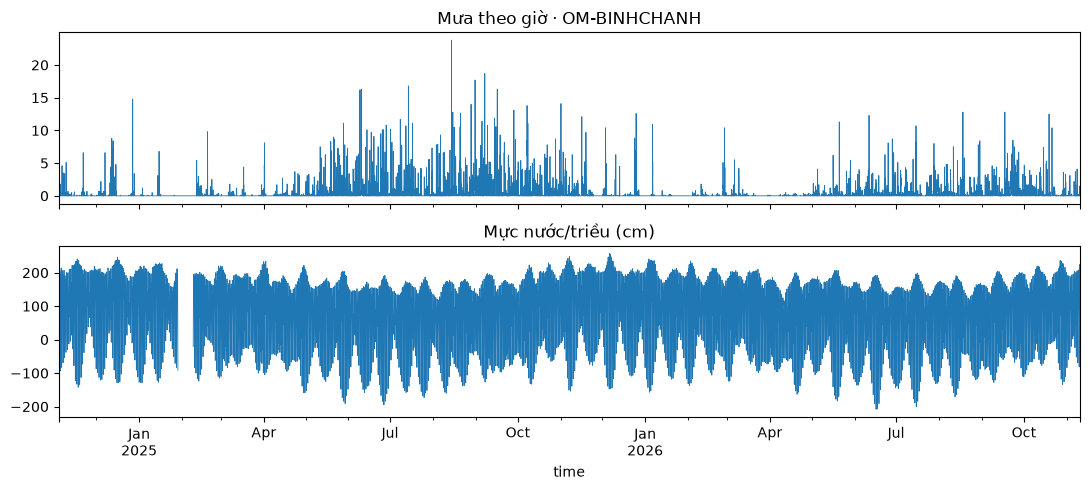

In [4]:
code = max(frames, key=lambda c: len(frames[c][0]))
df = frames[code][0].set_index("time")
fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
df["rain_mm"].plot(ax=ax[0], lw=.6, title=f"Mưa theo giờ · {code}"); df["water_level_cm"].plot(ax=ax[1], lw=.6, title="Mực nước/triều (cm)")
plt.tight_layout(); plt.show()

## 3. Làm sạch, chia theo thời gian, dựng cửa sổ

`build_datasets` làm sạch từng trạm, chia 70/15/15 theo thời gian (không trộn), fit bộ chuẩn hoá chỉ trên tập huấn luyện rồi tạo cửa sổ trượt.

In [5]:
from app.ai.forecasting.train import build_datasets
from app.ai.forecasting.preprocessing import LOOKBACK, HORIZON
data, scaler, boundaries = build_datasets(frames)
for k, v in data.items(): print(k, "X", v[0].shape, "y_rain", v[1].shape)
print("LOOKBACK =", LOOKBACK, "| HORIZON =", HORIZON)

train X (296328, 24, 5) y_rain (296328, 6)
val X (62952, 24, 5) y_rain (62952, 6)
test X (62952, 24, 5) y_rain (62952, 6)
LOOKBACK = 24 | HORIZON = 6


## 4. Huấn luyện GRU nhỏ trên mẫu con

In [6]:
import keras, time
from app.ai.forecasting.model import build_model
keras.utils.set_random_seed(42)
Xtr, rtr, _, _ = data["train"]; Xva, rva, _, _ = data["val"]; Xte, rte, _, _ = data["test"]
rng = np.random.default_rng(42)
def sub(n, *arrs):
    i = rng.choice(len(arrs[0]), min(n, len(arrs[0])), replace=False); return [a[i] for a in arrs]
Xtr_s, rtr_s = sub(20000, Xtr, rtr); Xva_s, rva_s = sub(5000, Xva, rva); Xte_s, rte_s = sub(5000, Xte, rte)
model = build_model("gru", heads=("rain",))
t0 = time.time()
hist = model.fit(Xtr_s, np.log1p(rtr_s), validation_data=(Xva_s, np.log1p(rva_s)), epochs=2, batch_size=256, verbose=0)
print(f"Huấn luyện {len(Xtr_s)} cửa sổ, 2 epoch, {time.time()-t0:.1f}s")
print({k: [round(x, 4) for x in v] for k, v in hist.history.items()})

Huấn luyện 20000 cửa sổ, 2 epoch, 6.6s
{'loss': [0.2458, 0.1031], 'val_loss': [0.08, 0.0809]}


## 5. Đánh giá trên tập kiểm thử (mẫu con)

So với hai đường cơ sở: *persistence* (giữ giá trị giờ cuối) và *climatology* (trung bình huấn luyện). `evaluate_rain` trả MAE/RMSE của mưa và chỉ số phát hiện mưa to (≥ 5 mm/h).

In [7]:
from app.ai.forecasting.train import evaluate_rain, baseline_predictions
pva = np.expm1(model.predict(Xva_s, verbose=0, batch_size=1024)); pte = np.expm1(model.predict(Xte_s, verbose=0, batch_size=1024))
b_rain, _, _ = baseline_predictions(Xte_s, scaler)
res = {"GRU (2 epoch)": evaluate_rain(pte, rte_s, pva, rva_s),
       "persistence": evaluate_rain(b_rain, rte_s, None, None),
       "climatology": evaluate_rain(np.full_like(rte_s, float(rtr_s.mean())), rte_s, None, None)}
table = pd.DataFrame({k: {"MAE": v["rainfall"]["mae"], "RMSE": v["rainfall"]["rmse"], "F1 mưa to": v["heavy_rain"]["f1"],
                          "precision": v["heavy_rain"]["precision"], "recall": v["heavy_rain"]["recall"]} for k, v in res.items()}).T
display(table.round(3))

,MAE,RMSE,F1 mưa to,precision,recall
GRU (2 epoch),0.357,0.92,0.041,0.047,0.037
persistence,0.457,1.14,0.026,0.035,0.020
climatology,0.416,0.95,0.000,0.000,0.000


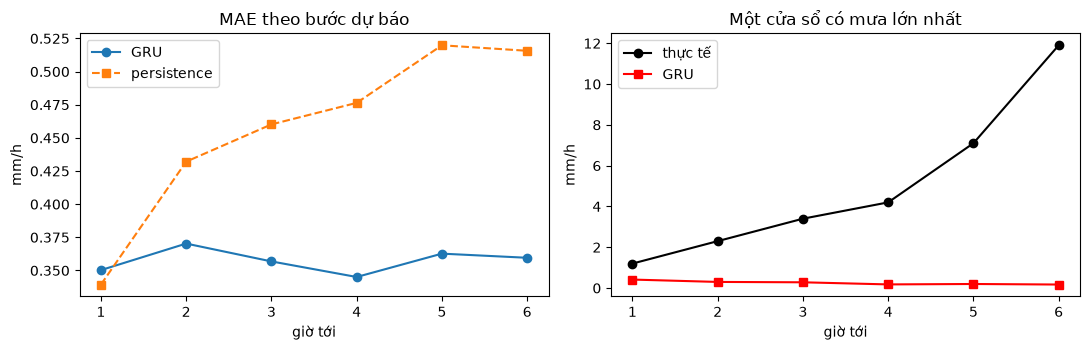

In [8]:
h = np.arange(1, HORIZON + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(h, np.abs(pte - rte_s).mean(0), "o-", label="GRU"); ax[0].plot(h, np.abs(b_rain - rte_s).mean(0), "s--", label="persistence")
ax[0].set(title="MAE theo bước dự báo", xlabel="giờ tới", ylabel="mm/h"); ax[0].legend()
k = int(np.argmax(rte_s.sum(1)))
ax[1].plot(h, rte_s[k], "k-o", label="thực tế"); ax[1].plot(h, pte[k], "r-s", label="GRU"); ax[1].set(title="Một cửa sổ có mưa lớn nhất", xlabel="giờ tới", ylabel="mm/h"); ax[1].legend()
plt.tight_layout(); plt.show()

**Nhận xét.** Chỉ 2 epoch trên mẫu con nên số liệu thấp hơn mô hình huấn luyện đầy đủ (`python -m app.ai.forecasting.train --epochs 8`). GRU có MAE thấp hơn persistence và climatology, nhưng F1 phát hiện mưa to vẫn rất thấp (mưa theo giờ thưa, lệch nặng, dữ liệu là mô hình lưới); cần đọc cùng chỉ số mưa to chứ không chỉ MAE.